# 📊 12. Regresión: resultados, residuos y comparación estadística

Los 28 modelos de regresión (7 modelos × 4 optimizadores) pronostican la venta del día siguiente. El capítulo sigue la secuencia que pide la guía:

1. Métricas del **bucle externo** (media ± desviación de los 4 folds) y en test.
2. Gráfico de **train, validación y test** con las predicciones.
3. **Residuos**: White (homocedasticidad), BDS (independencia), ACF + Ljung-Box, normalidad.
4. **Comparación estadística jerárquica**: MCS → Giacomini-White / Clark-West → Diebold-Mariano (HLN) con bootstrap estacionario → tamaño del efecto.
5. **Modelo en dos partes** para los días sin venta, como pidió la retroalimentación de la entrega 1.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_white
from statsmodels.tsa.stattools import acf, bds

from comun import estilo, a_log, SEED, AZUL, NARANJA, VERDE, AMARILLO, GRIS, PALETA, fechas_eje, cargar_panel
from datos import preparar, partir, X_COLS, folds_externos
from experimentos import armar_maestra, cargar
from metricas import metricas_reg
from modelos import MODELOS_REG, crear_modelo, ajustar
from estadistica import (friedman_nemenyi, diagrama_cd, model_confidence_set, giacomini_white, clark_west,
                         diebold_mariano, ic_estacionario, cohen_d, cliff_delta, magnitud_cliff, holm, ic_bca_negocios)

warnings.filterwarnings("ignore")
estilo()
train, test = partir(preparar())
maestra = armar_maestra()
reg = maestra[maestra["tarea"] == "reg"].copy()
NOMBRE = {"knn": "KNN", "ridge": "Ridge", "lasso": "Lasso", "arbol": "Árbol", "rf": "Random Forest", "xgb": "XGBoost", "svr": "SVR lineal"}
OPT = {"grid": "Grid", "random": "Random", "bayes": "Bayes", "genetico": "Genético"}
reg["etiqueta"] = reg["modelo"].map(NOMBRE) + " · " + reg["optimizador"].map(OPT)

/opt/miniconda3/envs/ml_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 📋 12.1 Métricas del bucle externo (las 28 combinaciones)

RMSE y MAE en COP (pedidos por el enunciado) y en log, WAPE y R². Cada valor es la **media ± desviación de los 4 folds externos**.

In [2]:
def pm(df, m, escala=1, dec=3):
    return (df[f"{m}_media"] / escala).round(dec).astype(str) + " ± " + (df[f"{m}_desv"] / escala).round(dec).astype(str)

tabla = pd.DataFrame({
    "modelo": reg["modelo"].map(NOMBRE), "optimizador": reg["optimizador"].map(OPT),
    "RMSE log": pm(reg, "rmse_log"), "MAE log": pm(reg, "mae_log"),
    "RMSE (M COP)": pm(reg, "rmse", 1e6, 2), "MAE (M COP)": pm(reg, "mae", 1e6, 2),
    "WAPE (%)": pm(reg, "wape", 0.01, 1), "R²": pm(reg, "r2"),
    "_orden": reg["rmse_log_media"], "min": (reg["seg_total"] / 60).round(1)})
tabla.sort_values("_orden").drop(columns="_orden").set_index(["modelo", "optimizador"])

RMSE log        MAE log RMSE (M COP)  \
modelo        optimizador                                              
Random Forest Grid         0.887 ± 0.127  0.291 ± 0.051  6.58 ± 1.49   
              Random        0.892 ± 0.13  0.294 ± 0.055  6.66 ± 1.53   
XGBoost       Random       0.894 ± 0.122  0.296 ± 0.048  7.61 ± 0.88   
Random Forest Bayes        0.895 ± 0.117  0.293 ± 0.047  6.82 ± 1.36   
XGBoost       Genético     0.898 ± 0.132  0.295 ± 0.049  7.36 ± 0.75   
              Bayes        0.898 ± 0.138  0.293 ± 0.051  6.79 ± 0.95   
Random Forest Genético       0.9 ± 0.117  0.294 ± 0.048  6.79 ± 1.41   
XGBoost       Grid         0.914 ± 0.119  0.297 ± 0.043  7.64 ± 0.47   
KNN           Genético     0.931 ± 0.111  0.305 ± 0.049  8.24 ± 1.42   
              Bayes        0.937 ± 0.115  0.307 ± 0.048    8.1 ± 1.1   
              Random       0.939 ± 0.118  0.303 ± 0.049  7.62 ± 1.13   
              Grid         0.944 ± 0.123  0.303 ± 0.048  7.45 ± 0.84   
Lasso         Bayes        0.949 ± 0.089  0.304 ± 0.037   6.6 ± 1.05   
              Genético     0.949 ± 0.089  0.304 ± 0.037  6.59 ± 1.05   
              Random        0.949 ± 0.09  0.304 ± 0.037  6.63 ± 1.08   
              Grid         0.949 ± 0.089  0.304 ± 0.037  6.59 ± 1.05   
Ridge         Genético      0.95 ± 0.089  0.304 ± 0.035  6.47 ± 0.98   
              Grid           0.95 ± 0.09  0.304 ± 0.036    6.5 ± 1.0   
              Random         0.95 ± 0.09  0.304 ± 0.036  6.49 ± 0.99   
              Bayes         0.951 ± 0.09  0.304 ± 0.036   6.5 ± 0.99   
Árbol         Bayes        0.952 ± 0.114  0.332 ± 0.041  8.39 ± 1.34   
              Grid         0.959 ± 0.116  0.325 ± 0.053  7.93 ± 1.62   
              Genético     0.961 ± 0.139   0.33 ± 0.057   8.01 ± 1.8   
              Random       0.973 ± 0.132  0.331 ± 0.059   7.8 ± 1.84   
SVR lineal    Grid         0.988 ± 0.096  0.308 ± 0.027  7.23 ± 1.07   
              Bayes        0.989 ± 0.098  0.304 ± 0.034   6.9 ± 0.89   
              Genético     0.989 ± 0.098  0.308 ± 0.033  7.35 ± 0.66   
              Random        0.99 ± 0.096  0.301 ± 0.039  6.68 ± 0.93   

                           MAE (M COP)    WAPE (%)             R²  min  
modelo        optimizador                                               
Random Forest Grid         2.69 ± 0.67  11.7 ± 3.3  0.966 ± 0.017 7.40  
              Random       2.73 ± 0.71  11.9 ± 3.5  0.965 ± 0.018 6.40  
XGBoost       Random       3.02 ± 0.53  13.1 ± 2.6  0.956 ± 0.012 2.20  
Random Forest Bayes         2.77 ± 0.6  12.1 ± 3.0  0.964 ± 0.016 9.00  
XGBoost       Genético     2.95 ± 0.42  12.8 ± 2.2   0.959 ± 0.01 2.80  
              Bayes        2.79 ± 0.48  12.1 ± 2.4  0.965 ± 0.012 2.50  
Random Forest Genético     2.77 ± 0.62  12.0 ± 3.1  0.964 ± 0.017 6.80  
XGBoost       Grid         3.05 ± 0.36  13.2 ± 1.9  0.956 ± 0.008 3.10  
KNN           Genético     3.41 ± 0.59  14.8 ± 3.0  0.947 ± 0.021 0.60  
              Bayes        3.36 ± 0.52  14.6 ± 2.7   0.95 ± 0.017 0.60  
              Random       3.19 ± 0.51  13.8 ± 2.7  0.955 ± 0.017 0.70  
              Grid          3.12 ± 0.4  13.5 ± 2.2  0.958 ± 0.013 0.50  
Lasso         Bayes        2.75 ± 0.52  11.9 ± 2.6  0.966 ± 0.013 0.30  
              Genético     2.74 ± 0.52  11.9 ± 2.6  0.966 ± 0.013 0.30  
              Random       2.76 ± 0.53  12.0 ± 2.6  0.966 ± 0.013 0.30  
              Grid         2.74 ± 0.52  11.9 ± 2.6  0.966 ± 0.013 0.30  
Ridge         Genético      2.7 ± 0.48  11.8 ± 2.4  0.968 ± 0.012 0.10  
              Grid          2.72 ± 0.5  11.8 ± 2.5  0.967 ± 0.012 0.10  
              Random        2.71 ± 0.5  11.8 ± 2.5  0.967 ± 0.012 0.10  
              Bayes         2.72 ± 0.5  11.8 ± 2.5  0.967 ± 0.012 0.10  
Árbol         Bayes        3.45 ± 0.55  15.0 ± 2.7  0.946 ± 0.018 0.50  
              Grid         3.27 ± 0.71  14.2 ± 3.5  0.951 ± 0.023 0.40  
              Genético     3.33 ± 0.79  14.5 ± 3.8  0.949 ± 0.025 0.40  
              Random       3.22 ± 0.83  14.0 ±

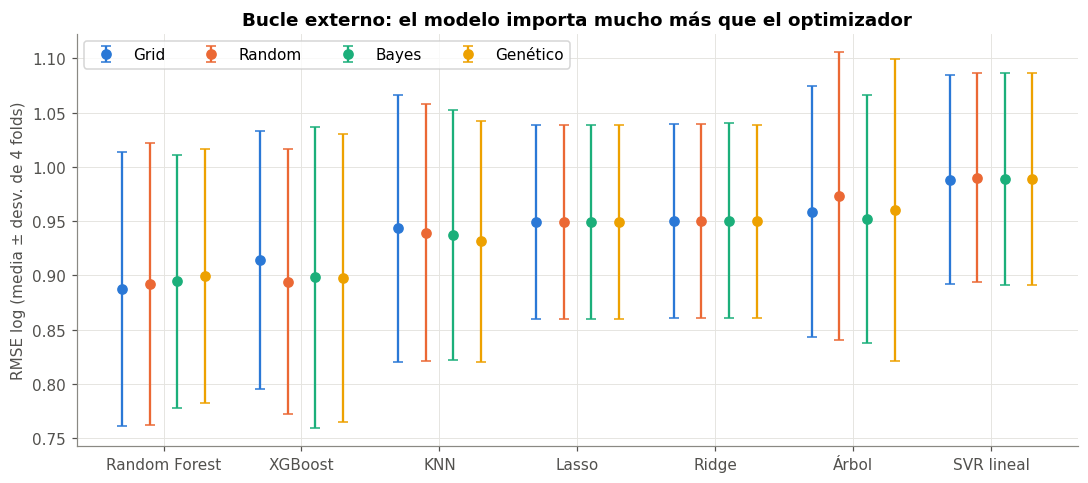

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
orden = reg.groupby("modelo")["rmse_log_media"].min().sort_values().index
for j, o in enumerate(["grid", "random", "bayes", "genetico"]):
    s = reg[reg["optimizador"] == o].set_index("modelo").loc[orden]
    x = np.arange(len(orden)) + (j - 1.5) * 0.2
    ax.errorbar(x, s["rmse_log_media"], yerr=s["rmse_log_desv"], fmt="o", color=PALETA[j], capsize=3, label=OPT[o])
ax.set_xticks(range(len(orden))); ax.set_xticklabels([NOMBRE[m] for m in orden])
ax.set_ylabel("RMSE log (media ± desv. de 4 folds)")
ax.set_title("Bucle externo: el modelo importa mucho más que el optimizador")
ax.legend(ncol=4)
plt.tight_layout()

### Interpretación

- **Los ensambles de árboles ganan con claridad.** Random Forest (RMSE log 0,887–0,900) y XGBoost (0,894–0,914) ocupan los 8 primeros lugares. Después vienen KNN (0,93–0,94), Lasso y Ridge (0,95), el árbol solo (0,95–0,97) y el SVR lineal de la entrega 1 (0,99). La retroalimentación sugería probar *gradient boosting*: los modelos no lineales captan interacciones (negocio irregular × día, nivel × volatilidad) que un modelo lineal global no ve.
- **El optimizador importa mucho menos que el modelo.** Dentro de un mismo modelo los 4 optimizadores quedan a menos de 0,03 entre sí, y en Ridge, Lasso y SVR prácticamente empatan: con 1 o 2 hiperparámetros cualquier método encuentra la zona buena. Donde más se separan es en XGBoost (6 hiperparámetros), y ahí el **grid** es el peor (0,914), porque su rejilla de 16 puntos solo prueba 2 valores por dimensión (cap. 10).
- **La desviación entre folds (±0,09 a ±0,14) es mayor que muchas de las diferencias entre modelos.** Los folds con festivos (1 y 2) son más difíciles para todos. Por eso hacen falta pruebas pareadas (12.5) y no basta con comparar medias.
- En COP el orden cambia un poco: Ridge y Lasso tienen RMSE en COP parecido al de Random Forest (6,5 contra 6,6 M). El RMSE en COP lo dominan los negocios grandes, donde un modelo lineal sobre el nivel ya funciona bien. En los negocios pequeños e irregulares, que pesan igual en log, los árboles sacan la ventaja.

## 🎯 12.2 El mejor de cada modelo, en test

Para cada uno de los 7 modelos se toma el optimizador con **menor RMSE log en el bucle externo** (la elección no mira test). Se agregan las dos líneas base de la entrega 1: **persistencia** ($\hat y_t = y_{t-1}$) e **ingenuo estacional** ($\hat y_t = y_{t-7}$).

In [4]:
mejor_opt = reg.loc[reg.groupby("modelo")["rmse_log_media"].idxmin()].set_index("modelo")
res = {m: cargar("reg", m, "ninguno", mejor_opt.loc[m, "optimizador"]) for m in MODELOS_REG}
pred_test = {NOMBRE[m]: res[m]["pred_test"]["pred"].to_numpy() for m in MODELOS_REG}
pred_test["Persistencia"] = np.expm1(test["lag1"].to_numpy())
pred_test["Ingenuo estacional"] = np.expm1(test["lag7"].to_numpy())
y_test = test["venta_total"].to_numpy()

tabla_test = pd.DataFrame({n: metricas_reg(y_test, p) for n, p in pred_test.items()}).T
tabla_test["optimizador"] = [OPT[mejor_opt.loc[m, "optimizador"]] for m in MODELOS_REG] + ["—", "—"]
tabla_test["RMSE (M COP)"], tabla_test["MAE (M COP)"] = tabla_test["rmse"] / 1e6, tabla_test["mae"] / 1e6
tabla_test["WAPE (%)"] = tabla_test["wape"] * 100
tabla_test = tabla_test[["optimizador", "rmse_log", "mae_log", "RMSE (M COP)", "MAE (M COP)", "WAPE (%)", "r2", "r2_log"]]
tabla_test = tabla_test.rename(columns={"rmse_log": "RMSE log", "mae_log": "MAE log", "r2": "R²", "r2_log": "R² log"}).sort_values("RMSE log")
mejor = tabla_test.index[0]
mejor_m = {v: k for k, v in NOMBRE.items()}[mejor]
segundo = [n for n in tabla_test.index if n in NOMBRE.values()][1]
segundo_m = {v: k for k, v in NOMBRE.items()}[segundo]
print(f"mejor en el bucle externo y en test: {mejor}; segundo: {segundo}")
tabla_test.round(3)

mejor en el bucle externo y en test: Random Forest; segundo: XGBoost


,optimizador,RMSE log,MAE log,RMSE (M COP),MAE (M COP),WAPE (%),R²,R² log
Random Forest,Grid,0.62,0.22,4.20,1.85,7.83,0.99,0.93
XGBoost,Random,0.64,0.22,5.34,2.14,9.03,0.98,0.92
KNN,Genético,0.64,0.24,6.12,2.60,10.98,0.97,0.92
Lasso,Bayes,0.68,0.23,4.65,2.05,8.65,0.98,0.91
Ridge,Genético,0.68,0.24,4.72,2.08,8.79,0.98,0.91
Árbol,Bayes,0.69,0.25,4.88,2.19,9.24,0.98,0.91
SVR lineal,Grid,0.69,0.24,6.48,2.64,11.15,0.97,0.91
Ingenuo estacional,—,0.85,0.26,4.74,2.11,8.90,0.98,0.86
Persistencia,—,0.92,0.30,7.88,3.28,13.83,0.95,0.84


### Interpretación

- **Random Forest es el mejor en test con todas las métricas**: RMSE log 0,62, MAE 1,85 M COP, WAPE 7,8 % y R² log 0,93. El SVR lineal (el modelo base de la entrega 1, reoptimizado) queda en 0,69, así que la mejora es de **10 % en RMSE log** y de 30 % en MAE en COP.
- **Contra el ingenuo estacional** (la línea base con la que el SVR casi empataba en la entrega 1), ahora sí hay una mejora clara **también en pesos**: WAPE 7,8 % contra 8,9 %, MAE 1,85 M contra 2,11 M y RMSE 4,20 M contra 4,74 M. En la entrega 1 el SVR empataba con el ingenuo en RMSE COP.
- La elección del mejor y del segundo (Random Forest y XGBoost) se hizo con el bucle externo y **coincide con el orden en test**. Es una buena señal de que la validación anidada estimó bien la generalización.
- El RMSE log en test (0,62) es menor que en el bucle externo (0,89). Test no tiene festivos (cap. 3) y el modelo final se entrena con 50 días, frente a 22–43 en los folds externos. La estimación del bucle externo es, entonces, **conservadora**.

## 🗓️ 12.3 Train, validación y test con las predicciones

Se suma la venta de todos los negocios por día (la serie que vería la gerencia) y se superponen las predicciones del mejor modelo:

- **train**: predicción del modelo final sobre los mismos días con los que se entrenó (ajuste dentro de muestra);
- **validación**: predicciones del bucle externo (cada semana la predice un modelo que no la vio);
- **test**: predicciones del modelo final para 3 – 23 sep.

Abajo, lo mismo para un negocio típico de cada tamaño.

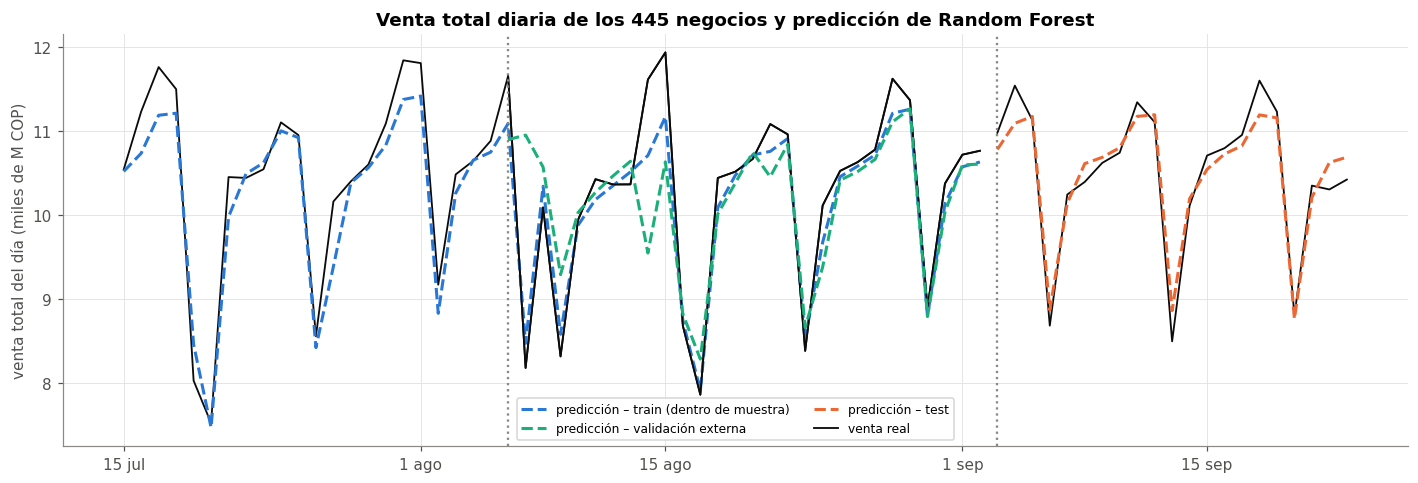

In [5]:
r = res[mejor_m]
modelo_final = crear_modelo("reg", mejor_m, r["params_final"])
ajustar(modelo_final, train[X_COLS], train["venta_total"].to_numpy(), "reg", mejor_m, "ninguno")
tr = train.assign(pred=modelo_final.predict(train[X_COLS]))
va = train.iloc[r["pred_val"]["fila"]].assign(pred=r["pred_val"]["pred"].to_numpy())
te = test.assign(pred=r["pred_test"]["pred"].to_numpy())

fig, ax = plt.subplots(figsize=(13, 4.5))
for df, color, nombre in [(tr, AZUL, "train (dentro de muestra)"), (va, VERDE, "validación externa"), (te, NARANJA, "test")]:
    s = df.groupby("fecha")[["venta_total", "pred"]].sum() / 1e9
    ax.plot(s.index, s["venta_total"], color="#0b0b0b", lw=1.2)
    ax.plot(s.index, s["pred"], color=color, lw=2, ls="--", label=f"predicción – {nombre}")
ax.plot([], [], color="#0b0b0b", lw=1.2, label="venta real")
for f in [va["fecha"].min(), te["fecha"].min()]:
    ax.axvline(f, color=GRIS, ls=":")
fechas_eje(ax, pd.concat([tr["fecha"], te["fecha"]]).unique())
ax.set_ylabel("venta total del día (miles de M COP)")
ax.set_title(f"Venta total diaria de los 445 negocios y predicción de {mejor}")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()

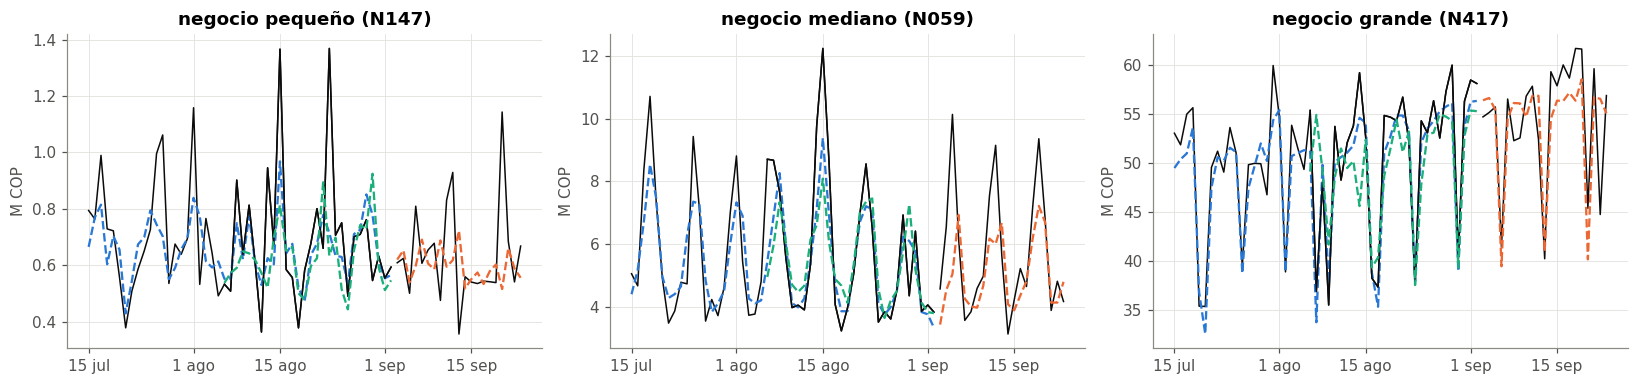

In [6]:
# un negocio por tamaño (pequeño, mediano, grande): el de venta mediana de cada tercil
nivel = train.groupby("negocio")["media7"].median()
terciles = pd.qcut(nivel, 3, labels=["pequeño", "mediano", "grande"])
ejemplos = {t: (nivel[terciles == t] - nivel[terciles == t].median()).abs().idxmin() for t in ["pequeño", "mediano", "grande"]}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for i, (t, neg) in enumerate(ejemplos.items()):
    for df, color in [(tr, AZUL), (va, VERDE), (te, NARANJA)]:
        s = df[df["negocio"] == neg].sort_values("fecha")
        ax[i].plot(s["fecha"], s["venta_total"] / 1e6, color="#0b0b0b", lw=1)
        ax[i].plot(s["fecha"], s["pred"] / 1e6, color=color, lw=1.5, ls="--")
    fechas_eje(ax[i], pd.concat([tr["fecha"], te["fecha"]]).unique())
    ax[i].set_title(f"negocio {t} ({neg})"); ax[i].set_ylabel("M COP")
plt.tight_layout()

### Interpretación

- **A nivel agregado** el modelo sigue muy de cerca la venta total diaria en los tres tramos. Dentro de muestra (train, línea azul, que se superpone también al tramo de validación) el ajuste es muy cercano: un bosque con hojas de 2 observaciones memoriza en parte. Por eso la métrica válida es la de validación y test, no la de train.
- En **validación** se ven los festivos. El **viernes 7 ago** el modelo no anticipa la caída (predice ~10,9 mil M y se vendieron ~8,2 mil M), porque en el fold que lo predice solo hay un festivo previo (20 jul) para aprender su efecto. El **lunes 17 ago** sí se acerca, porque ya cae en el patrón bajo de los lunes. Con solo 3 festivos en el periodo, el efecto festivo es lo que el modelo aprende peor (cap. 6.5).
- En **test** la predicción captura el ciclo semanal (sábados altos, domingos y lunes bajos) sin desfases.
- Por negocio: en el **grande** el pronóstico es muy preciso en términos relativos; en el **pequeño** la serie es mucho más ruidosa y el modelo se queda en el nivel medio. Es el patrón de la entrega 1: error típico de ~6 % en negocios grandes y ~20 % en pequeños.

## 🔎 12.4 Análisis de residuos (test, mejor modelo)

Los residuos se analizan en la escala en la que se entrena el modelo, $e = \log(1+y) - \log(1+\hat y)$. En COP la varianza crece con el tamaño del negocio por construcción, y eso no dice nada del modelo.

días sin venta en test: 37 (0.40%) -> 55% del error cuadrático en log
residuos con venta: media 0.0373, asimetría 4.23, curtosis exceso 123.6, Jarque-Bera p = 0.0e+00


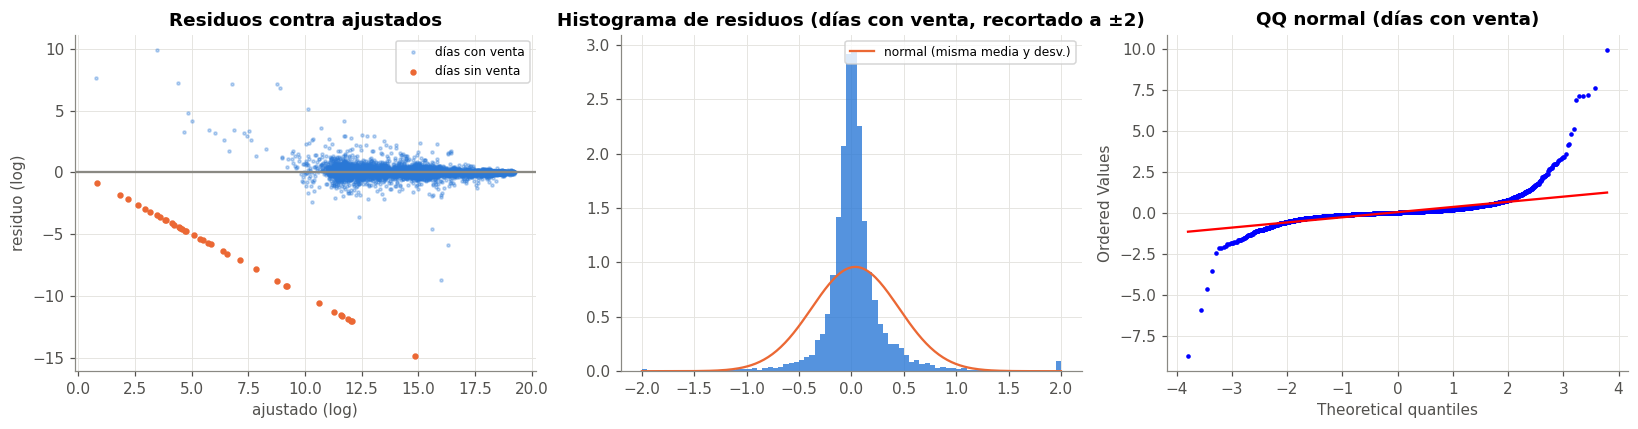

In [7]:
te["res"] = a_log(te["venta_total"]) - a_log(te["pred"])
te["ajuste"] = a_log(te["pred"])
cero = te["venta_total"] <= 0
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(te.loc[~cero, "ajuste"], te.loc[~cero, "res"], s=4, alpha=0.3, color=AZUL, label="días con venta")
ax[0].scatter(te.loc[cero, "ajuste"], te.loc[cero, "res"], s=10, color=NARANJA, label="días sin venta")
ax[0].axhline(0, color=GRIS); ax[0].set_xlabel("ajustado (log)"); ax[0].set_ylabel("residuo (log)")
ax[0].set_title("Residuos contra ajustados"); ax[0].legend(fontsize=8)
sin = te.loc[~cero, "res"]
ax[1].hist(sin.clip(-2, 2), bins=80, density=True, color=AZUL, alpha=0.8)
xx = np.linspace(-2, 2, 200)
ax[1].plot(xx, stats.norm.pdf(xx, sin.mean(), sin.std()), color=NARANJA, label="normal (misma media y desv.)")
ax[1].set_title("Histograma de residuos (días con venta, recortado a ±2)"); ax[1].legend(fontsize=8)
stats.probplot(sin, dist="norm", plot=ax[2]); ax[2].set_title("QQ normal (días con venta)")
ax[2].get_lines()[0].set_markersize(2)
plt.tight_layout()
print(f"días sin venta en test: {cero.sum()} ({cero.mean():.2%}) -> {(te.loc[cero, 'res'] ** 2).sum() / (te['res'] ** 2).sum():.0%} del error cuadrático en log")
jb = stats.jarque_bera(sin)
print(f"residuos con venta: media {sin.mean():.4f}, asimetría {stats.skew(sin):.2f}, curtosis exceso {stats.kurtosis(sin):.1f}, Jarque-Bera p = {jb.pvalue:.1e}")

Ljung-Box (rezago 7) por negocio: rechaza al 5 % en 12.3% de negocios; con Holm en 1.1%


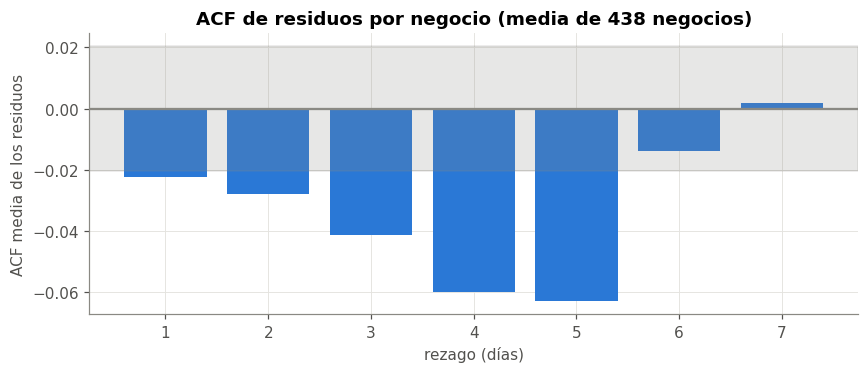

In [8]:
# ACF de los residuos: la de cada negocio (promedio) y Ljung-Box por negocio con Holm
te = te.sort_values(["negocio", "fecha"])
acfs, pvals = [], []
for neg, s in te.groupby("negocio")["res"]:
    if s.std() > 0 and len(s) == 21:
        acfs.append(acf(s, nlags=7, fft=False))
        pvals.append(acorr_ljungbox(s, lags=[7])["lb_pvalue"].iloc[0])
acfs, pvals = np.array(acfs), np.array(pvals)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(1, 8), acfs[:, 1:].mean(0), color=AZUL)
ax.axhline(0, color=GRIS)
banda = 1.96 / np.sqrt(21 * len(acfs))
ax.axhspan(-banda, banda, color=GRIS, alpha=0.2)
ax.set_xlabel("rezago (días)"); ax.set_ylabel("ACF media de los residuos")
ax.set_title(f"ACF de residuos por negocio (media de {len(acfs)} negocios)")
plt.tight_layout()
print(f"Ljung-Box (rezago 7) por negocio: rechaza al 5 % en {np.mean(pvals < 0.05):.1%} de negocios; con Holm en {np.mean(holm(pvals) < 0.05):.1%}")

### Interpretación

- Los **37 días sin venta de test (0,4 %) son el 55 % del error cuadrático en log** (en la entrega 1 con el SVR eran el 71 %). Siguen dominando el error, pero menos.
- En los días con venta los residuos tienen media 0,04 (un leve sesgo a **subestimar**), asimetría positiva y colas mucho más pesadas que la normal (curtosis en exceso 124). Jarque-Bera rechaza la normalidad. El histograma muestra un centro **más puntudo** que la normal y colas largas: la mayoría de los días se predicen muy bien y unos pocos muy mal. Con más de 9 000 observaciones cualquier prueba de normalidad rechaza. Lo importante es que la normalidad **no es un supuesto** de un bosque aleatorio, y los intervalos de confianza de este capítulo se hacen con bootstrap, no con fórmulas normales.
- **ACF:** la autocorrelación media de los residuos por negocio es pequeña en todos los rezagos. Ljung-Box (rezago 7) rechaza en el 12 % de los negocios sin corrección, y **en solo 1,1 % con Holm**. No queda estructura temporal importante sin explicar, igual que en la entrega 1.

### Pruebas de White y BDS para los 7 modelos

- **White**: regresa los residuos al cuadrado sobre las variables, sus cuadrados y sus productos cruzados. $H_0$: varianza constante (homocedasticidad). Se usa una muestra de 3 000 filas de test y las 6 variables numéricas principales (con las 19 columnas serían 190 regresores y la prueba pierde sentido).
- **BDS** (Brock, Dechert y Scheinkman): $H_0$: los residuos son **i.i.d.** Detecta dependencia no lineal que la ACF no ve. Se aplica a la serie diaria del residuo medio (21 días), con dimensiones de inmersión 2 y 3, y también a la serie de cada negocio concatenada en orden temporal.

In [9]:
vars_white = ["lag1", "lag7", "media7", "std7", "nivel", "dias_sin_venta7"]
muestra = test.sample(3000, random_state=SEED).index
filas = []
for nombre, p in pred_test.items():
    e = a_log(y_test) - a_log(p)
    ex = test.loc[muestra, vars_white].fillna(0).to_numpy()
    ex = np.column_stack([np.ones(len(ex)), (ex - ex.mean(0)) / ex.std(0)])
    _, p_white, _, _ = het_white(e[muestra], ex)
    diario = pd.Series(e).groupby(test["fecha"].to_numpy()).mean().to_numpy()
    p_bds_dia = bds(diario, max_dim=3)[1]
    orden_neg = np.lexsort((test["fecha"].to_numpy(), test["negocio"].to_numpy()))
    p_bds_neg = bds(e[orden_neg], max_dim=3)[1]
    met = metricas_reg(y_test, p)
    filas.append({"modelo": nombre, "RMSE log": met["rmse_log"], "MAE log": met["mae_log"],
                  "RMSE (M COP)": met["rmse"] / 1e6, "MAE (M COP)": met["mae"] / 1e6,
                  "p White": p_white, "p BDS diario (m=2)": p_bds_dia[0], "p BDS diario (m=3)": p_bds_dia[1],
                  "p BDS apilado (m=2)": p_bds_neg[0]})
supuestos = pd.DataFrame(filas).set_index("modelo").sort_values("RMSE log")
supuestos.round(4)

,RMSE log,MAE log,RMSE (M COP),MAE (M COP),p White,p BDS diario (m=2),p BDS diario (m=3),p BDS apilado (m=2)
modelo,,,,,,,,
Random Forest,0.62,0.22,4.20,1.86,0.00,0.82,0.06,0.00
XGBoost,0.64,0.22,5.34,2.14,0.00,0.55,0.00,0.00
KNN,0.64,0.24,6.12,2.60,0.00,0.51,0.05,0.00
Lasso,0.68,0.23,4.65,2.05,0.00,0.13,0.00,0.00
Ridge,0.68,0.24,4.72,2.08,0.00,0.34,0.00,0.00
Árbol,0.69,0.25,4.88,2.19,0.00,0.14,0.00,0.00
SVR lineal,0.69,0.24,6.48,2.64,0.00,0.42,0.34,0.00
Ingenuo estacional,0.85,0.26,4.74,2.11,0.00,0.41,0.77,0.00
Persistencia,0.92,0.30,7.88,3.28,0.00,0.58,0.21,0.00


### Interpretación: White y BDS

- **White rechaza la homocedasticidad en todos los modelos** (p ≈ 0). La varianza del error en log depende de las variables: es mayor en negocios pequeños e irregulares (`std7` alto, `dias_sin_venta7` > 0). Esto no invalida los pronósticos, pero sí dice que un **intervalo de predicción** debería ser más ancho para esos negocios. Además justifica usar errores robustos (bootstrap) en las comparaciones.
- **BDS sobre la serie diaria del residuo medio:** con dimensión 2 no rechaza en ningún modelo (p entre 0,13 y 0,82). Con dimensión 3, Random Forest queda en el límite (p = 0,06) y los modelos lineales rechazan. El residuo agregado del mejor modelo **no muestra dependencia no lineal clara**. Hay que tomarlo con cautela: son solo 21 días.
- **BDS sobre los residuos apilados** (negocio por negocio) rechaza en todos los modelos, incluidas las líneas base. Es esperable: al apilar negocios se mezclan series con varianzas muy distintas (la heterocedasticidad de White), y BDS es sensible a eso. No es necesariamente dependencia temporal.
- **Conclusión:** el mejor modelo deja residuos sin autocorrelación relevante (Ljung-Box con Holm), pero **heterocedásticos y de colas pesadas**. Las fuentes son los negocios irregulares y los días sin venta, el mismo diagnóstico del capítulo 4b.

## ⚖️ 12.5 Comparación estadística jerárquica

### Paso 0: Friedman y Nemenyi (diagrama de diferencia crítica)

Como en clasificación, primero se pregunta si **algún** modelo difiere. Los bloques son los **negocios** (la unidad independiente, cap. 1): para cada negocio se calcula el RMSE log de cada modelo en sus 28 días de validación externa. Con 445 bloques, Friedman tiene mucha potencia.

7 modelos (mejor optimizador de cada uno): χ² = 496.5, p = 4.8e-104, CD = 0.426, N = 447 negocios
28 combinaciones: χ² = 1844.5, p = 0.0e+00, CD = 2.044


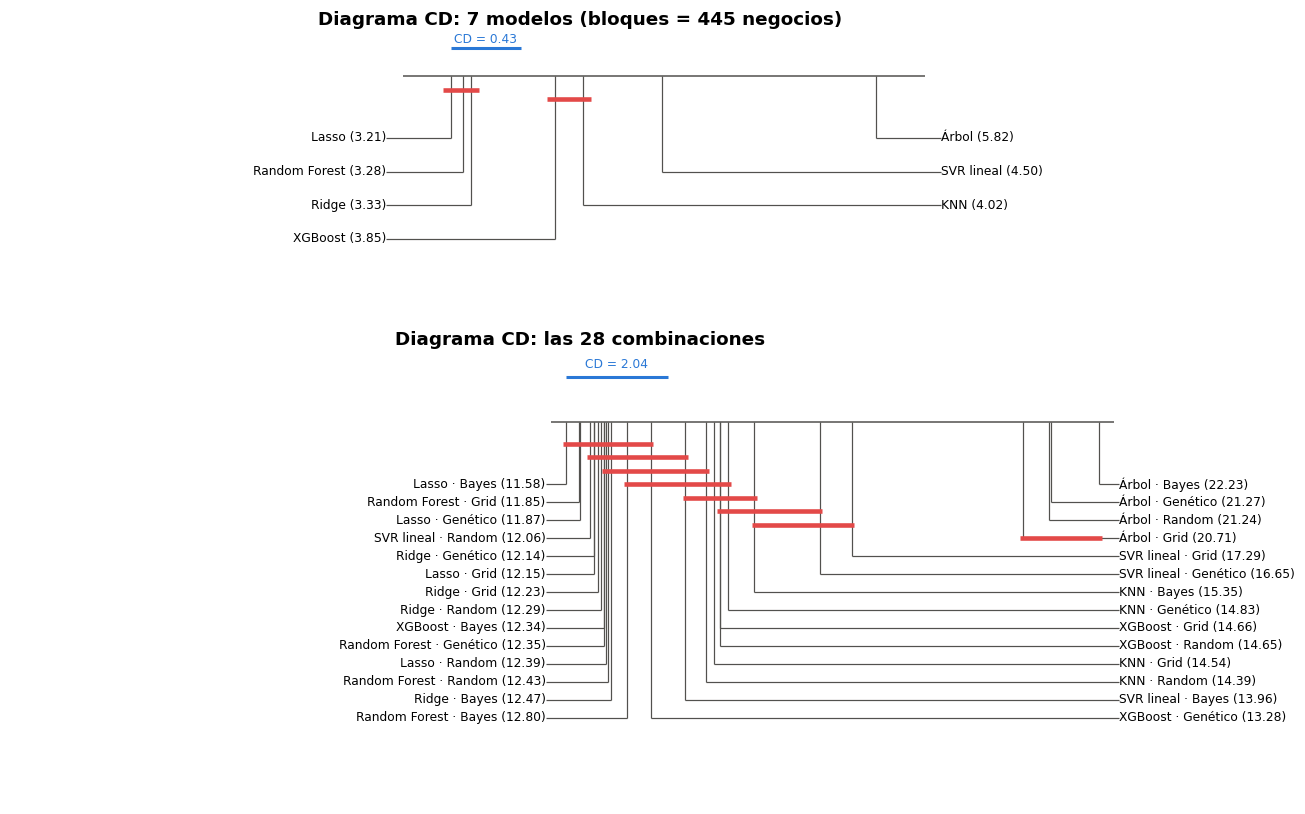

In [10]:
# pérdida por negocio y por día en la validación externa, para las 28 combinaciones
val_rows = None
perd_neg, perd_dia = {}, {}
for _, fila in reg.iterrows():
    rr = cargar("reg", fila["modelo"], "ninguno", fila["optimizador"])
    pv = rr["pred_val"]
    sub = train.iloc[pv["fila"]]
    e2 = (a_log(sub["venta_total"].to_numpy()) - a_log(pv["pred"].to_numpy())) ** 2
    perd_neg[fila["etiqueta"]] = pd.Series(e2).groupby(sub["negocio"].to_numpy()).mean().pow(0.5)
    perd_dia[fila["etiqueta"]] = pd.Series(e2).groupby(sub["fecha"].to_numpy()).mean()
    if val_rows is None:
        val_rows = sub
perd_neg, perd_dia = pd.DataFrame(perd_neg), pd.DataFrame(perd_dia)
# líneas base en las mismas filas de validación
for nombre, col in [("Persistencia", "lag1"), ("Ingenuo estacional", "lag7")]:
    e2 = (a_log(val_rows["venta_total"].to_numpy()) - val_rows[col].to_numpy()) ** 2
    perd_dia[nombre] = pd.Series(e2).groupby(val_rows["fecha"].to_numpy()).mean()

mejores = {NOMBRE[m]: f"{NOMBRE[m]} · {OPT[mejor_opt.loc[m, 'optimizador']]}" for m in MODELOS_REG}
fn7 = friedman_nemenyi(perd_neg[list(mejores.values())].rename(columns={v: k for k, v in mejores.items()}))
fn28 = friedman_nemenyi(perd_neg)
print(f"7 modelos (mejor optimizador de cada uno): χ² = {fn7['chi2']:.1f}, p = {fn7['p']:.1e}, CD = {fn7['cd']:.3f}, N = {fn7['n']} negocios")
print(f"28 combinaciones: χ² = {fn28['chi2']:.1f}, p = {fn28['p']:.1e}, CD = {fn28['cd']:.3f}")
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), gridspec_kw={"height_ratios": [1, 1.6]})
diagrama_cd(fn7["rangos"], fn7["cd"], ax[0], "Diagrama CD: 7 modelos (bloques = 445 negocios)")
diagrama_cd(fn28["rangos"], fn28["cd"], ax[1], "Diagrama CD: las 28 combinaciones")
plt.tight_layout()

### Interpretación

- **Friedman rechaza con fuerza** que los 7 modelos sean equivalentes (χ² = 496, p ≈ 10⁻¹⁰⁴, con 447 negocios como bloques).
- **Nemenyi (CD = 0,43).** El resultado es distinto al de las métricas promedio. Por negocio, **Lasso (rango 3,21), Random Forest (3,28) y Ridge (3,33) empatan**: sus diferencias son mucho menores que la CD. XGBoost (3,85) y KNN (4,02) quedan peor que Random Forest, el SVR lineal (4,50) más atrás y el árbol simple (5,82) último.
- **Cómo se concilia con que Random Forest tenga el menor RMSE log medio:** Friedman usa **rangos** por negocio y no la magnitud del error. En el negocio *típico* (estable), un modelo lineal sobre el nivel reciente pronostica tan bien como el bosque. La ventaja del bosque está en **pocos negocios difíciles** (irregulares, con días sin venta), donde los modelos lineales se equivocan por mucho. Eso pesa en el promedio del error pero no en el rango. Las pruebas basadas en la magnitud de la pérdida (MCS y DM, abajo) sí favorecen a los ensambles.
- Con las 28 combinaciones (CD = 2,04), las variantes del mismo modelo con distintos optimizadores **quedan conectadas**: la diferencia entre optimizadores no es significativa.


### Paso 1: Model Confidence Set

El MCS (Hansen, Lunde y Nason, 2011) parte de las **28 combinaciones + 2 líneas base** y elimina, una a una, las significativamente peores hasta que las que quedan no se pueden distinguir del mejor. Se usa la serie de **pérdida diaria** (error cuadrático medio en log de todos los negocios, 28 días del bucle externo), un bootstrap por bloques de 3 días (los días tienen autocorrelación semanal, cap. 6) y $\alpha = 0{,}10$.

In [11]:
mcs = model_confidence_set(perd_dia, alfa=0.10, bloque=3, reps=2000)
mcs["rango de pérdida (por día)"] = perd_dia.rank(axis=1).mean()[mcs.index]
finalistas = list(mcs.index[mcs["en el conjunto"]])
print(f"{len(finalistas)} modelos en el conjunto de confianza al 90 %")
mcs.round(4)

7 modelos en el conjunto de confianza al 90 %


,p MCS,en el conjunto,pérdida media,rango de pérdida (por día)
Model name,,,,
Random Forest · Grid,1.00,True,0.80,8.21
Random Forest · Random,0.46,True,0.81,8.36
Random Forest · Bayes,0.46,True,0.81,8.82
XGBoost · Random,0.45,True,0.81,9.96
XGBoost · Genético,0.43,True,0.82,9.89
Random Forest · Genético,0.46,True,0.82,8.82
XGBoost · Bayes,0.46,True,0.82,10.61
XGBoost · Grid,0.07,False,0.85,12.50
KNN · Genético,0.00,False,0.88,13.75


### Interpretación

- El **MCS al 90 % retiene 7 combinaciones**: las 4 de Random Forest y 3 de XGBoost (Random, Genético, Bayes). XGBoost con Grid queda justo afuera (p = 0,07). Todos los demás modelos y las dos líneas base se eliminan (p ≤ 0,01).
- La conclusión que **controla el *data snooping*** (sin corregir a mano 406 pares) es que **los ensambles de árboles son estadísticamente superiores** al resto, pero entre Random Forest y XGBoost (y entre sus optimizadores) **no se puede afirmar** cuál es mejor con 28 días de validación.
- El ingenuo estacional tiene la peor pérdida en validación (1,75), peor incluso que la persistencia. En los folds externos hay días cuyo "mismo día de la semana anterior" fue festivo, el mismo fenómeno que se vio en la entrega 1.

### Paso 2: Giacomini-White entre finalistas y Clark-West para el caso anidado

- **Giacomini-White** (habilidad predictiva **condicional**) se aplica a los pares de finalistas del MCS que **no están anidados** (por ejemplo, un ensamble de árboles frente a otro). Instrumentos: constante y la diferencia de pérdida del día anterior.
- **Clark-West** se usa para la comparación **anidada**: el ingenuo estacional ($\log \hat y_t = $ `lag7`) es un caso particular de cualquier modelo que tenga `lag7` entre sus variables (coeficiente 1 y los demás 0). Se compara el mejor modelo contra él, por negocio-día y por día.

In [12]:
from itertools import combinations
top = finalistas[:4] if len(finalistas) >= 2 else list(mcs.index[:3])
filas = []
for a, b in combinations(top, 2):
    d = (perd_dia[a] - perd_dia[b]).to_numpy()
    est, p = giacomini_white(d)
    filas.append({"A": a, "B": b, "pérdida media A − B": d.mean(), "GW": est, "p crudo": p})
gw = pd.DataFrame(filas)
if len(gw):
    gw["p Holm"] = holm(gw["p crudo"])
    gw["p BH"] = __import__("statsmodels.stats.multitest", fromlist=["multipletests"]).multipletests(gw["p crudo"], method="fdr_bh")[1]
gw.round(4)

,A,B,pérdida media A − B,GW,p crudo,p Holm,p BH
0,Random Forest · Grid,Random Forest · Random,-0.01,4.57,0.10,0.61,0.61
1,Random Forest · Grid,Random Forest · Bayes,-0.01,2.93,0.23,1.00,0.61
2,Random Forest · Grid,XGBoost · Random,-0.01,1.54,0.46,1.00,0.61
3,Random Forest · Random,Random Forest · Bayes,-0.00,1.88,0.39,1.00,0.61
4,Random Forest · Random,XGBoost · Random,-0.00,0.73,0.70,1.00,0.70
5,Random Forest · Bayes,XGBoost · Random,-0.00,1.35,0.51,1.00,0.61


In [13]:
# Clark-West: ingenuo estacional (restringido) contra el mejor modelo (amplio), en test y en validación externa
mejor_etq = mejores[mejor]
rr = res[mejor_m]
pv = rr["pred_val"]; sub = train.iloc[pv["fila"]]
filas = []
for donde, y_, f_r, f_a in [("validación externa", a_log(sub["venta_total"].to_numpy()), sub["lag7"].to_numpy(), a_log(pv["pred"].to_numpy())),
                            ("test", a_log(y_test), test["lag7"].to_numpy(), a_log(pred_test[mejor]))]:
    t, p = clark_west(y_, f_r, f_a)
    filas.append({"datos": donde, "modelo restringido": "Ingenuo estacional", "modelo amplio": mejor, "t CW": t, "p (unilateral)": p})
pd.DataFrame(filas).round(4)

,datos,modelo restringido,modelo amplio,t CW,p (unilateral)
0,validación externa,Ingenuo estacional,Random Forest,8.75,0.00
1,test,Ingenuo estacional,Random Forest,5.62,0.00


### Interpretación

- **Giacomini-White** entre los 4 primeros finalistas del MCS: ningún par rechaza después de Holm ni de Benjamini-Hochberg (p ajustados ≥ 0,61). No hay evidencia de que uno de los finalistas pronostique mejor **ni en promedio ni condicionado al día anterior**. Esto confirma el MCS.
- **Clark-West** (ingenuo estacional anidado en Random Forest): rechaza con claridad en validación (t = 8,8) y en test (t = 5,6). Corregido el sesgo del DM en modelos anidados, la información adicional del bosque sí mejora el pronóstico frente a "lo mismo que la semana pasada".

### Paso 3: Diebold-Mariano (HLN) entre el mejor y el segundo, con bootstrap estacionario

Confirmación puntual entre los dos primeros. Se aplica en las dos series de pérdida diaria disponibles: la validación externa (28 días) y el test (21 días). El intervalo de la diferencia media de pérdida se calcula con **bootstrap estacionario** (Politis y Romano, 1994; bloques de longitud media 3), que respeta la dependencia entre días. Como tamaños de efecto: **d de Cohen** de la diferencia diaria y **delta de Cliff** entre las pérdidas de los 445 negocios.

In [14]:
seg_etq = mejores[segundo]
e2_test = {n: pd.Series((a_log(y_test) - a_log(p)) ** 2).groupby(test["fecha"].to_numpy()).mean() for n, p in pred_test.items()}
filas = []
for donde, A, B in [("validación externa", perd_dia[mejor_etq], perd_dia[seg_etq]), ("test", e2_test[mejor], e2_test[segundo])]:
    d = (A - B).to_numpy()
    dm, p = diebold_mariano(d)
    lo, hi = ic_estacionario(d, bloque=3)
    filas.append({"datos": donde, "A (mejor)": mejor, "B (segundo)": segundo, "días": len(d), "pérdida A − B": d.mean(),
                  "IC 95 % bootstrap estacionario": f"[{lo:.4f}, {hi:.4f}]", "DM (HLN)": dm, "p crudo": p, "d de Cohen": cohen_d(d)})
# también contra el ingenuo estacional, la línea base más fuerte
for donde, A, B in [("validación externa", perd_dia[mejor_etq], perd_dia["Ingenuo estacional"]), ("test", e2_test[mejor], e2_test["Ingenuo estacional"])]:
    d = (A - B).to_numpy()
    dm, p = diebold_mariano(d)
    lo, hi = ic_estacionario(d, bloque=3)
    filas.append({"datos": donde, "A (mejor)": mejor, "B (segundo)": "Ingenuo estacional", "días": len(d), "pérdida A − B": d.mean(),
                  "IC 95 % bootstrap estacionario": f"[{lo:.4f}, {hi:.4f}]", "DM (HLN)": dm, "p crudo": p, "d de Cohen": cohen_d(d)})
dmt = pd.DataFrame(filas)
dmt["p Holm"] = holm(dmt["p crudo"])
dmt.round(4)

,datos,A (mejor),B (segundo),días,pérdida A − B,IC 95 % bootstrap estacionario,DM (HLN),p crudo,d de Cohen,p Holm
0,validación externa,Random Forest,XGBoost,28,-0.01,"[-0.0254, 0.0019]",-1.17,0.25,-0.22,0.25
1,test,Random Forest,XGBoost,21,-0.02,"[-0.0310, -0.0078]",-2.01,0.06,-0.44,0.12
2,validación externa,Random Forest,Ingenuo estacional,28,-0.95,"[-1.3170, -0.6213]",-7.79,0.00,-1.47,0.00
3,test,Random Forest,Ingenuo estacional,21,-0.34,"[-0.4708, -0.2312]",-5.22,0.00,-1.14,0.00


In [15]:
# delta de Cliff entre las pérdidas por negocio (validación externa) del mejor contra cada uno de los otros 6
filas = []
for n, etq in mejores.items():
    if n == mejor:
        continue
    dc = cliff_delta(perd_neg[mejor_etq], perd_neg[etq])
    w = stats.wilcoxon(perd_neg[mejor_etq], perd_neg[etq])
    filas.append({"mejor": mejor, "contra": n, "RMSE log medio por negocio (contra)": perd_neg[etq].mean(),
                  "delta de Cliff": dc, "magnitud": magnitud_cliff(dc), "p Wilcoxon": w.pvalue})
cl = pd.DataFrame(filas)
cl["p Holm"] = holm(cl["p Wilcoxon"])
print(f"RMSE log medio por negocio de {mejor}: {perd_neg[mejor_etq].mean():.4f}")
cl.sort_values("delta de Cliff").round(4)

RMSE log medio por negocio de Random Forest: 0.4583


,mejor,contra,RMSE log medio por negocio (contra),delta de Cliff,magnitud,p Wilcoxon,p Holm
3,Random Forest,Árbol,0.52,-0.16,pequeño,0.00,0.00
5,Random Forest,SVR lineal,0.49,-0.07,despreciable,0.00,0.00
0,Random Forest,KNN,0.48,-0.07,despreciable,0.00,0.00
4,Random Forest,XGBoost,0.47,-0.03,despreciable,0.00,0.00
1,Random Forest,Ridge,0.47,0.00,despreciable,0.65,1.00
2,Random Forest,Lasso,0.47,0.00,despreciable,0.58,1.00


### Interpretación

- **Random Forest contra XGBoost (Diebold-Mariano con HLN):** en validación externa la diferencia diaria es −0,01 (a favor del bosque) pero no significativa (p = 0,25), y el intervalo del bootstrap estacionario contiene el 0. En test la diferencia es −0,02 y el intervalo **no** contiene el 0 ([−0,031; −0,008]), pero el DM no llega al 5 % (p = 0,06; 0,12 con Holm). El tamaño del efecto es **pequeño a mediano** (d de Cohen −0,22 y −0,44).
  - Lectura: Random Forest es ligeramente mejor de forma consistente, pero con 21–28 días la evidencia **no es concluyente**. El DM asintótico y el bootstrap estacionario no coinciden exactamente porque la muestra es corta; el bootstrap no supone normalidad, y por eso la guía lo pide como complemento.
- **Random Forest contra el ingenuo estacional:** la diferencia es enorme y muy significativa en validación y en test (p Holm < 0,001, d de Cohen −1,47 y −1,14, efectos **grandes**).
- **Delta de Cliff por negocio:** frente al árbol simple el efecto es pequeño (−0,16); frente a KNN, SVR y XGBoost es **despreciable** (≤ 0,07) aunque Wilcoxon rechace. Frente a Ridge y Lasso es **0**: en el negocio *típico* el bosque no es mejor que un modelo lineal. Su ventaja media viene de **pocos negocios difíciles** (los irregulares), donde los modelos lineales fallan mucho más. Es un caso claro en que un p-valor muy chico no implica un efecto grande para la mayoría.

### Intervalos de confianza BCa en test

Bootstrap **por negocios** (las filas de un negocio no son independientes) con el método **BCa** (*bias-corrected and accelerated*), porque la distribución del RMSE es asimétrica. 1 000 réplicas.

In [16]:
neg_test = test["negocio"].to_numpy()
filas = []
for n in [mejor, segundo, "XGBoost", "Ingenuo estacional", "Persistencia"]:
    if any(f["modelo"] == n for f in filas):
        continue
    p = pred_test[n]
    el = a_log(y_test) - a_log(p)
    rmse_f = lambda i, el=el: np.sqrt(np.mean(el[i] ** 2))
    mae_f = lambda i, p=p: np.mean(np.abs(y_test[i] - p[i])) / 1e6
    lo, hi = ic_bca_negocios(neg_test, rmse_f)
    lo2, hi2 = ic_bca_negocios(neg_test, mae_f)
    filas.append({"modelo": n, "RMSE log": np.sqrt(np.mean(el ** 2)), "IC 95 % RMSE log": f"[{lo:.3f}, {hi:.3f}]",
                  "MAE (M COP)": np.mean(np.abs(y_test - p)) / 1e6, "IC 95 % MAE": f"[{lo2:.2f}, {hi2:.2f}]"})
pd.DataFrame(filas).set_index("modelo").round(3)

,RMSE log,IC 95 % RMSE log,MAE (M COP),IC 95 % MAE
modelo,,,,
Random Forest,0.62,"[0.499, 0.777]",1.85,"[1.66, 2.18]"
XGBoost,0.64,"[0.512, 0.795]",2.14,"[1.87, 2.63]"
Ingenuo estacional,0.85,"[0.670, 1.056]",2.11,"[1.89, 2.47]"
Persistencia,0.92,"[0.723, 1.195]",3.28,"[2.90, 3.84]"


### Interpretación

- Los intervalos BCa son **anchos** (RMSE log de Random Forest entre 0,50 y 0,78) porque dependen de pocos negocios con días sin venta: según cuáles entren en la réplica, el RMSE sube o baja mucho. Esa asimetría es justo el caso en que el BCa corrige al percentil.
- Los intervalos de Random Forest y XGBoost se **solapan casi por completo**, consistente con el MCS. El de Random Forest **no se solapa** con el de la persistencia en MAE ([1,66; 2,18] contra [2,90; 3,84]) y apenas toca el del ingenuo estacional.

## 🎲 12.6 Sensibilidad a la semilla

Random Forest y XGBoost tienen azar interno (muestreo de filas y columnas). Se reentrena el mejor de cada uno con sus hiperparámetros finales y **5 semillas** distintas, y se mide el RMSE log en test. Si la variación por semilla fuera comparable a la diferencia entre modelos, la diferencia no sería confiable.

In [17]:
filas = []
for m in ["rf", "xgb"]:
    for s in [42, 7, 2026, 11, 123]:
        mod = crear_modelo("reg", m, res[m]["params_final"], semilla=s)
        ajustar(mod, train[X_COLS], train["venta_total"].to_numpy(), "reg", m, "ninguno")
        filas.append({"modelo": NOMBRE[m], "semilla": s, "RMSE log test": metricas_reg(y_test, mod.predict(test[X_COLS]))["rmse_log"]})
sem = pd.DataFrame(filas)
sem_res = sem.groupby("modelo")["RMSE log test"].agg(["mean", "std", "min", "max"])
sem_res["rango"] = sem_res["max"] - sem_res["min"]
print(f"diferencia entre los dos modelos (medias): {abs(sem_res['mean'].diff().iloc[-1]):.4f}")
sem_res.round(4)

diferencia entre los dos modelos (medias): 0.0135


,mean,std,min,max,rango
modelo,,,,,
Random Forest,0.62,0.00,0.62,0.63,0.01
XGBoost,0.64,0.00,0.63,0.64,0.01


### Interpretación

- Cambiar la semilla mueve el RMSE log en test **menos de 0,01** (desviación ≈ 0,003) en los dos modelos. La diferencia entre Random Forest y XGBoost (0,014) es mayor que el rango de cada uno por semilla, así que el orden entre ellos **no es un accidente de la semilla**. Pero es del mismo orden de magnitud, lo que coincide con que las pruebas no la declaren significativa.

## 🧩 12.7 Modelo en dos partes para los días sin venta

La retroalimentación de la entrega 1 sugirió un **modelo en dos partes** (*hurdle*), porque los días sin venta concentran casi todo el error en log:

1. **Clasificador**: $\hat p_t = P(\text{venta}_t = 0 \mid x_t)$ con XGBoost **sin balanceo**: aquí se necesita una probabilidad bien calibrada, no una clase, y el balanceo la sesga hacia arriba.
2. **Regresor**: el mejor modelo de regresión, entrenado **solo con días con venta**, da $\hat z_t = E[\log(1+y_t) \mid y_t > 0, x_t]$.
3. **Combinación**: en log, el pronóstico que minimiza el error cuadrático es $(1 - \hat p_t)\,\hat z_t + \hat p_t \cdot 0$.

Se usa un solo ajuste con los hiperparámetros ya elegidos (no se agrega otra búsqueda).

In [18]:
from xgboost import XGBClassifier
from modelos import _preprocesador
from sklearn.pipeline import Pipeline

y_tr = train["venta_total"].to_numpy()
clf_cero = Pipeline([("pre", _preprocesador()),
                     ("modelo", XGBClassifier(tree_method="hist", n_estimators=300, learning_rate=0.05, max_depth=4,
                                              random_state=SEED, n_jobs=4, eval_metric="logloss"))])
clf_cero.fit(train[X_COLS], (y_tr <= 0).astype(int))
p_cero = clf_cero.predict_proba(test[X_COLS])[:, 1]

pos = y_tr > 0
reg_pos = crear_modelo("reg", mejor_m, res[mejor_m]["params_final"])
ajustar(reg_pos, train.loc[pos, X_COLS], y_tr[pos], "reg", mejor_m, "ninguno")
z_pos = a_log(reg_pos.predict(test[X_COLS]))
z_dos = (1 - p_cero) * z_pos
pred_dos = np.expm1(z_dos)

from sklearn.metrics import roc_auc_score
cero_test = y_test <= 0
print(f"AUC del clasificador de días sin venta en test: {roc_auc_score(cero_test, p_cero):.3f} ({cero_test.sum()} días sin venta)")
comp = pd.DataFrame({f"{mejor} (una parte)": metricas_reg(y_test, pred_test[mejor]),
                     "dos partes": metricas_reg(y_test, pred_dos)}).T
for nombre, z in [(f"{mejor} (una parte)", a_log(pred_test[mejor])), ("dos partes", z_dos)]:
    e = a_log(y_test) - z
    comp.loc[nombre, "RMSE log días con venta"] = np.sqrt(np.mean(e[~cero_test] ** 2))
    comp.loc[nombre, "RMSE log días sin venta"] = np.sqrt(np.mean(e[cero_test] ** 2))
comp[["rmse_log", "RMSE log días con venta", "RMSE log días sin venta", "mae_log", "wape", "r2_log"]].round(4)

AUC del clasificador de días sin venta en test: 0.980 (37 días sin venta)


,rmse_log,RMSE log días con venta,RMSE log días sin venta,mae_log,wape,r2_log
Random Forest (una parte),0.62,0.42,7.32,0.22,0.08,0.93
dos partes,0.62,0.43,7.15,0.21,0.08,0.93


In [19]:
d = ((a_log(y_test) - z_dos) ** 2 - (a_log(y_test) - a_log(pred_test[mejor])) ** 2)
d_dia = pd.Series(d).groupby(test["fecha"].to_numpy()).mean().to_numpy()
dm, p = diebold_mariano(d_dia)
lo, hi = ic_estacionario(d_dia)
lo_n, hi_n = ic_bca_negocios(neg_test, lambda i: np.mean(d[i]))
print(f"dos partes − una parte (error cuadrático en log): media diaria {d_dia.mean():.4f}, IC 95 % bootstrap estacionario [{lo:.4f}, {hi:.4f}]")
print(f"DM (HLN) = {dm:.2f}, p = {p:.3f}; IC 95 % BCa por negocios [{lo_n:.4f}, {hi_n:.4f}]")

dos partes − una parte (error cuadrático en log): media diaria -0.0034, IC 95 % bootstrap estacionario [-0.0265, 0.0222]
DM (HLN) = -0.20, p = 0.842; IC 95 % BCa por negocios [-0.0373, 0.0434]


### Interpretación

- El clasificador de días sin venta es **muy bueno ordenando** (AUC = 0,98): los días sin venta se anuncian con días sin venta previos (las rachas del cap. 4b).
- Pero el **modelo en dos partes casi no mejora** el error total: RMSE log 0,62 en los dos. En los días sin venta baja de 7,32 a 7,15 y en los días con venta sube un poco (0,42 a 0,43). La diferencia **no es significativa** (DM p = 0,84; los dos intervalos contienen el 0).
- **Por qué:** en log, un día sin venta con pronóstico de 10 M tiene un error de ~16. Para reducirlo de verdad el modelo tendría que dar probabilidades cercanas a 1, y solo las da en los días que **ya venían** de una racha sin venta, que el bosque ya predecía bajos por `lag1` = 0. Los días sin venta "sorpresa" (negocio normal que de pronto no vende) son impredecibles con información del día anterior, con una o con dos partes.
- **Conclusión:** la retroalimentación tenía razón en que los días sin venta concentran el error. Pero el problema es de **información**, no de forma del modelo. Lo que sí se aprovecha de esto es la **tarea de clasificación** (cap. 13), que convierte esa señal en una alerta.